# 🚀 Practice Day 33

**📅 Date:** 2026-10-13  
📁 Category: Phase 2 · Pandas 심화(GroupBy&Pivot) (Round 3/5)

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Practice groupby aggregation and pivot_table cross-tabulation across two dimensions — hotel branch and room type
  (groupby 집계와 pivot_table 교차분석을 지점·객실타입 두 차원에 걸쳐 연습하기)
- Find which branch and which room type drive the most revenue, and where they intersect
  (매출을 가장 많이 견인하는 지점과 객실타입, 그리고 그 둘이 만나는 지점 찾기)

---
# 📂 Dataset

**Dataset Name:** Meridian Hotels — 지점별·객실타입별 월간 예약 데이터 / Meridian Hotels — Monthly Bookings by Branch & Room Type

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** 6 months (Jan-Jun 2024) of monthly booking counts and revenue for a 6-branch hotel chain (SoHo, Midtown, Astoria, Forest Hills, Williamsburg, Chelsea), broken down by 4 room types (Standard, Deluxe, Suite, Executive). 144 rows total (6 branches × 4 room types × 6 months), revenue in USD, clean — no missing values or duplicates. The focus is building single-dimension groupby summaries and a branch × room-type pivot table.
(호텔 체인 6개 지점(SoHo/Midtown/Astoria/Forest Hills/Williamsburg/Chelsea)에서 6개월(2024년 1~6월) 동안 4개 객실타입(Standard/Deluxe/Suite/Executive)별로 집계된 월간 예약건수와 매출 데이터입니다. 총 144행(6지점×4객실타입×6개월), 매출은 USD이고, 결측치·중복 없이 깨끗합니다. groupby로 지점별·객실타입별 집계를, pivot_table로 지점×객실타입 교차표를 만드는 데 초점을 둡니다.)

## Dataset Preview

In [1]:
# Dataset Preview
import pandas as pd
import numpy as np

np.random.seed(42)
rng = np.random.default_rng(42)

# --- Generate monthly bookings for a 6-branch hotel chain, by room type ---
branches = ['SoHo', 'Midtown', 'Astoria', 'Forest Hills', 'Williamsburg', 'Chelsea']
branch_mult = {'SoHo': 1.3, 'Midtown': 1.4, 'Astoria': 0.95, 'Forest Hills': 0.8, 'Williamsburg': 1.05, 'Chelsea': 1.15}

room_types = ['Standard', 'Deluxe', 'Suite', 'Executive']
base_bookings = {'Standard': 100, 'Deluxe': 52, 'Suite': 22, 'Executive': 14}
avg_price = {'Standard': 120, 'Deluxe': 180, 'Suite': 320, 'Executive': 450}  # USD per booking

months = pd.date_range('2024-01-01', periods=6, freq='MS')

rows = []
for b in branches:
    for rt in room_types:
        for i, m in enumerate(months):
            noise = rng.normal(1.0, 0.10)
            bookings = base_bookings[rt] * branch_mult[b] * noise
            bookings = max(1, int(round(bookings)))
            price_noise = rng.normal(1.0, 0.04)
            revenue = int(round(bookings * avg_price[rt] * price_noise))  # nearest USD
            rows.append({'month': m, 'branch': b, 'room_type': rt, 'bookings': bookings, 'revenue': revenue})

df = pd.DataFrame(rows).sort_values(['month', 'branch', 'room_type']).reset_index(drop=True)

df.head(10)


,month,branch,room_type,bookings,revenue
0,2024-01-01,Astoria,Deluxe,54,9048
1,2024-01-01,Astoria,Executive,14,6244
2,2024-01-01,Astoria,Standard,82,9447
3,2024-01-01,Astoria,Suite,19,6124
4,2024-01-01,Chelsea,Deluxe,70,12103
5,2024-01-01,Chelsea,Executive,15,6450
6,2024-01-01,Chelsea,Standard,105,12552
7,2024-01-01,Chelsea,Suite,26,8657
8,2024-01-01,Forest Hills,Deluxe,42,7857
9,2024-01-01,Forest Hills,Executive,13,5901


## Dataset Information

In [2]:
# Dataset Information
df.info()
print("\nShape:", df.shape)
df.describe(include='all')


<class 'pandas.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   month      144 non-null    datetime64[us]
 1   branch     144 non-null    str           
 2   room_type  144 non-null    str           
 3   bookings   144 non-null    int64         
 4   revenue    144 non-null    int64         
dtypes: datetime64[us](1), int64(2), str(2)
memory usage: 5.8 KB

Shape: (144, 5)


,month,branch,room_type,bookings,revenue
count,144,144,144,144.000000,144.000000
unique,NaN,6,4,NaN,NaN
top,NaN,Astoria,Deluxe,NaN,NaN
freq,NaN,24,36,NaN,NaN
mean,2024-03-16 20:00:00,NaN,NaN,51.805556,9571.048611
min,2024-01-01 00:00:00,NaN,NaN,10.000000,4548.000000
25%,2024-02-01 00:00:00,NaN,NaN,19.000000,7407.000000
50%,2024-03-16 12:00:00,NaN,NaN,36.500000,9083.500000
75%,2024-05-01 00:00:00,NaN,NaN,75.250000,11105.000000
max,2024-06-01 00:00:00,NaN,NaN,150.000000,18049.000000


---
# ❓ Business Questions

1. **(Analysis)** Which branch generated the highest total revenue over the period, and which the lowest?
   (기간 전체 총매출 기준 최고·최저 지점은?)
2. **(Analysis)** Which room type generated the highest total revenue overall, and which the lowest?
   (전체 객실타입 중 최고·최저 매출 타입은?)
3. **(Analysis)** When you cross-tabulate branch and room type, which single combination generated the most revenue — and which the least?
   (지점×객실타입으로 교차분석했을 때, 가장 매출이 높은 조합과 가장 낮은 조합은?)
4. **(Visualization)** How do the six branches compare on total revenue?
   (6개 지점의 총매출을 비교하면?)
5. **(Visualization)** How does revenue break down across the branch × room-type grid all at once?
   (지점×객실타입 조합별 매출은 한눈에 어떻게 보이는가?)

---
# 🔍 Data Cleaning Check


In [3]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("Missing values")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDtypes")
print(df.dtypes)

print("\nColumn names")
print(df.columns.tolist())

obj_cols = df.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(df[obj_cols].nunique())


Missing values
month        0
branch       0
room_type    0
bookings     0
revenue      0
dtype: int64

Duplicate rows: 0

Dtypes
month        datetime64[us]
branch                  str
room_type               str
bookings              int64
revenue               int64
dtype: object

Column names
['month', 'branch', 'room_type', 'bookings', 'revenue']

Text columns — unique counts
branch       6
room_type    4
dtype: int64


---
# 📊 Analysis

## Question 1

**Question:** Which branch generated the highest total revenue over the period, and which the lowest? (기간 총매출 기준 최고·최저 지점은?)

**Result:** Midtown is highest at **$284,424**. Forest Hills is lowest at **$166,360**.  
(가장 높은 지점은 Midtown $284,424, 가장 낮은 지점은 Forest Hills $166,360)

**Insight:** Midtown is **$118,064** above Forest Hills and **$8,510** above the second place, SoHo (**$275,914**).  
(Midtown은 Forest Hills보다 $118,064, 2위 SoHo($275,914)보다 $8,510 높음)


In [4]:
# Question 1: total revenue by branch

branch_rev = df.groupby('branch')['revenue'].sum().sort_values(ascending=False)

branch_rev

branch
Midtown         284424
SoHo            275914
Chelsea         242119
Williamsburg    214449
Astoria         194965
Forest Hills    166360
Name: revenue, dtype: int64

## Question 2

**Question:** Which room type generated the highest total revenue overall, and which the lowest? (최고·최저 매출 객실타입은?)

**Result:** Standard is highest at **$470,324**. Executive is lowest at **$248,435**.  
(가장 높은 타입은 Standard $470,324, 가장 낮은 타입은 Executive $248,435)

**Insight:** Standard is **$221,889** above Executive and **$97,667** above the second place, Deluxe (**$372,657**).  
(Standard는 Executive보다 $221,889, 2위 Deluxe($372,657)보다 $97,667 높음)


In [5]:
# Question 2: total revenue by room_type
room_rev = df.groupby('room_type')['revenue'].sum().sort_values(ascending=False)

room_rev

room_type
Standard     470324
Deluxe       372657
Suite        286815
Executive    248435
Name: revenue, dtype: int64

## Question 3

**Question:** When you cross-tabulate branch and room type, which single combination generated the most revenue — and which the least? (지점×객실타입 교차분석에서 최고·최저 조합은?)

**Result:** The highest combination is Midtown · Standard at **$98,784**. The lowest is Forest Hills · Executive at **$32,115**.  
(가장 높은 조합은 Midtown·Standard $98,784, 가장 낮은 조합은 Forest Hills·Executive $32,115)

**Insight:** Midtown · Standard is **$66,669** above Forest Hills · Executive. That is the highest branch crossed with the highest room type, and the lowest branch with the lowest room type.  
(Midtown·Standard는 Forest Hills·Executive보다 $66,669 높음. 최고 지점과 최고 객실타입이 만나고, 최저 지점과 최저 객실타입이 만남)


In [6]:
# Question 3: branch x room_type cross-tab
pivot = df.pivot_table(index='branch', columns='room_type', values='revenue', aggfunc='sum')

stacked = pivot.stack()
print(stacked.idxmax(), stacked.max())
print(stacked.idxmin(), stacked.min())

('Midtown', 'Standard') 98784
('Forest Hills', 'Executive') 32115


---
# 📈 Visualization

**Chart 1:** Bar chart — total revenue by branch (막대그래프: 지점별 총매출)

*Interpretation:* The bars fall from Midtown (**$284,424**) to SoHo (**$275,914**), Chelsea (**$242,119**), Williamsburg (**$214,449**), Astoria (**$194,965**), and Forest Hills (**$166,360**). The first two bars are close, then the drop is steeper.  
(막대는 Midtown $284,424, SoHo $275,914, Chelsea $242,119, Williamsburg $214,449, Astoria $194,965, Forest Hills $166,360 순으로 낮아짐. 앞 두 막대는 가깝고 그다음부터 더 가파르게 떨어짐)

---

**Chart 2:** Heatmap — revenue by branch × room type (히트맵: 지점×객실타입별 매출)

*Interpretation:* The darkest cell is top-left, Midtown · Standard at **$98,784**. The lightest cell is bottom-right, Forest Hills · Executive at **$32,115**. Color fades down each column and to the right across each row.  
(가장 진한 칸은 왼쪽 위 Midtown·Standard $98,784. 가장 연한 칸은 오른쪽 아래 Forest Hills·Executive $32,115. 색은 각 열에서 아래로, 각 행에서 오른쪽으로 옅어짐)


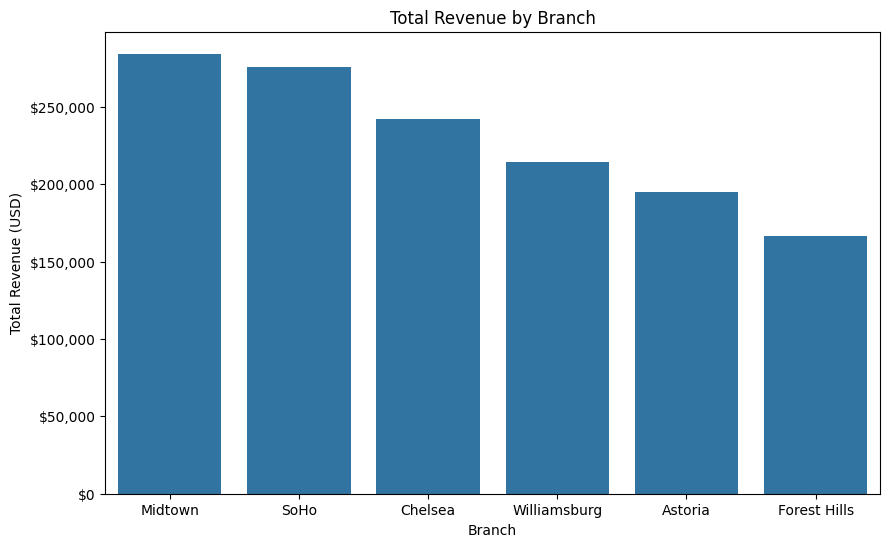

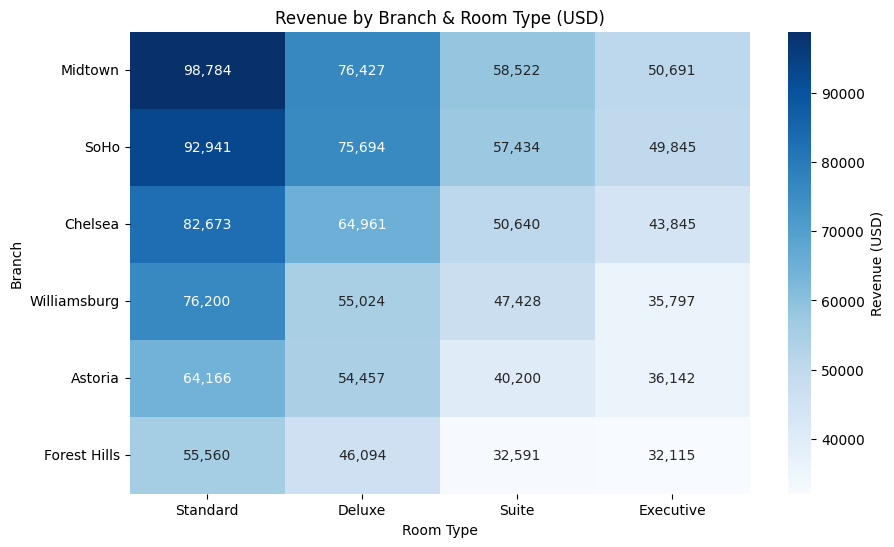

In [7]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Chart 1: total revenue by branch (bar)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=branch_rev.index, y=branch_rev.values, ax=ax)
ax.yaxis.set_major_formatter('${x:,.0f}')
ax.set_title('Total Revenue by Branch')
ax.set_xlabel('Branch')
ax.set_ylabel('Total Revenue (USD)')
plt.show()

# Chart 2: branch x room_type revenue (heatmap)

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(pivot.reindex(index=branch_rev.index, columns=room_rev.index),
            annot=True, fmt=',.0f', cmap='Blues', cbar_kws={'label': 'Revenue (USD)'}, ax=ax)
ax.set_title('Revenue by Branch & Room Type (USD)')
ax.set_xlabel('Room Type')
ax.set_ylabel('Branch')
ax.tick_params(axis='y', rotation=0)
plt.show()


---
# 💼 Business Insights
*What did I discover?*

- Midtown leads the six branches at **$284,424**, and Forest Hills is last at **$166,360**.  
  (6개 지점 중 Midtown이 $284,424로 1위, Forest Hills가 $166,360으로 마지막)
- Standard rooms bring in **$470,324**, the most of the four types. Executive is lowest at **$248,435**.  
  (4개 타입 중 Standard가 $470,324로 가장 많고, Executive가 $248,435로 가장 적음)
- The single strongest cell is Midtown · Standard at **$98,784**. The weakest is Forest Hills · Executive at **$32,115**.  
  (한 칸으로 가장 강한 조합은 Midtown·Standard $98,784. 가장 약한 조합은 Forest Hills·Executive $32,115)  


---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Keep Midtown Standard stocked. That one cell is **$98,784**, the top of the 24 combinations.  
   (Midtown Standard 재고를 유지하기. 그 한 칸이 $98,784로 24개 조합 중 최고)
2. Look at Forest Hills Executive (**$32,115**) and Forest Hills Suite (**$32,591**). Those two cells sit at the bottom of the heatmap.  
   (Forest Hills Executive($32,115)와 Forest Hills Suite($32,591)를 보기. 히트맵 맨 아래 두 칸)
3. Protect Standard across branches. It is the highest room type at **$470,324**, and it is the darkest column on the heatmap.  
   (지점 전체에서 Standard를 지키기. 객실타입 합계 $470,324로 가장 높고, 히트맵에서 가장 진한 열)  


---
# ❌ Mistakes
*What mistakes did I make today?*

- Q1 used `idxmax` and `idxmin` on the raw `revenue` column, so it picked one month-row instead of a branch total.  
  (Q1에서 revenue 열에 idxmax, idxmin을 써서 지점 합계가 아니라 한 달 행을 고름)
- I thought I had to scan the pivot by eye for the highest and lowest cell.  
  (교차표의 최고·최저 칸을 눈으로 찾아야 한다고 생각함)
- Q1 and Q2 first assigned `branch_rev` and `room_rev` and stopped, so the cells printed nothing.  
  (Q1, Q2에서 branch_rev와 room_rev만 넣고 멈춰서 셀에 아무것도 안 나옴)  


---
# ✅ What I Learned
*Today's biggest lesson*

- Highest and lowest by group come from `groupby(...).sum().sort_values()`, not from `idxmax` on the raw rows.  
  (그룹 최고·최저는 원본 행의 idxmax가 아니라 groupby 합계를 정렬해서 봄)
- `pivot.stack()` then `idxmax()` and `idxmin()` name the highest and lowest cell without reading the grid by hand.  
  (pivot.stack() 뒤에 idxmax, idxmin을 쓰면 칸을 눈으로 읽지 않아도 최고·최저 조합이 나옴)
- `pivot.reindex(index=branch_rev.index, columns=room_rev.index)` puts the highest totals at the top and left, so the heatmap fades toward the bottom-right.  
  (reindex로 합계가 큰 지점·타입을 위와 왼쪽에 두면 히트맵이 오른쪽 아래로 옅어짐)  


---
# 🧠 Reflection

**What was difficult?**  
Choosing the right unit for highest and lowest, and lining up the heatmap.  
(최고·최저를 어떤 단위로 볼지 고르는 것과 히트맵 순서를 맞추는 것)

**Why?**  
`idxmax` on the table picks a single row, and a default pivot sorts names A to Z, not by revenue.  
(표에 idxmax를 쓰면 행 하나만 고르고, 기본 pivot은 매출이 아니라 이름순)

**How did I solve it?**  
Grouped first, then stacked the pivot for `idxmax`. Reindexed the heatmap with those same sorted indexes.  
(먼저 묶고, pivot을 stack해서 idxmax를 씀. 히트맵은 그 정렬된 인덱스로 reindex)

**What would I do differently next time?**  
Write the group totals before looking for a max, and reuse those indexes for the heatmap.  
(최댓값을 찾기 전에 그룹 합계를 먼저 만들고, 히트맵에도 그 인덱스를 그대로 쓰기)


---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★☆☆☆  
Group totals, the pivot max and min, and why the heatmap fades to the bottom-right are clear.  
(그룹 합계, 교차표 최고·최저, 히트맵이 오른쪽 아래로 옅어지는 이유는 이해함)

**Confidence**  
★★★★★★☆☆☆☆  

**Difficulty**  
★★★★★☆☆☆☆☆  
The pandas steps were short. The hard part was not using `idxmax` on the raw rows.  
(pandas 단계는 짧았고, 어려운 부분은 원본 행에 idxmax를 쓰지 않는 것이었음)


---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Practice Day 34 — SQL basics (Round 3/5)  
  (DuckDB SQL 기초 복습)  
